In [31]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/haninehamrouni15/ashrae-energy-prediction/building_metadata.csv
/kaggle/input/datasets/haninehamrouni15/ashrae-energy-prediction/sample_submission.csv
/kaggle/input/datasets/haninehamrouni15/ashrae-energy-prediction/test.csv
/kaggle/input/datasets/haninehamrouni15/ashrae-energy-prediction/train.csv
/kaggle/input/datasets/haninehamrouni15/ashrae-energy-prediction/weather_test.csv
/kaggle/input/datasets/haninehamrouni15/ashrae-energy-prediction/weather_train.csv
/kaggle/input/datasets/haninehamrouni15/archive/Plant_1_Generation_Data.csv
/kaggle/input/datasets/haninehamrouni15/archive/Plant_1_Weather_Sensor_Data.csv
/kaggle/input/datasets/haninehamrouni15/archive/Plant_2_Generation_Data.csv
/kaggle/input/datasets/haninehamrouni15/archive/Plant_2_Weather_Sensor_Data.csv


In [32]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

print("Bibliothèques importées avec succès !")

Bibliothèques importées avec succès !


In [33]:
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/kaggle/input/datasets/haninehamrouni15/ashrae-energy-prediction/building_metadata.csv
/kaggle/input/datasets/haninehamrouni15/ashrae-energy-prediction/sample_submission.csv
/kaggle/input/datasets/haninehamrouni15/ashrae-energy-prediction/test.csv
/kaggle/input/datasets/haninehamrouni15/ashrae-energy-prediction/train.csv
/kaggle/input/datasets/haninehamrouni15/ashrae-energy-prediction/weather_test.csv
/kaggle/input/datasets/haninehamrouni15/ashrae-energy-prediction/weather_train.csv
/kaggle/input/datasets/haninehamrouni15/archive/Plant_1_Generation_Data.csv
/kaggle/input/datasets/haninehamrouni15/archive/Plant_1_Weather_Sensor_Data.csv
/kaggle/input/datasets/haninehamrouni15/archive/Plant_2_Generation_Data.csv
/kaggle/input/datasets/haninehamrouni15/archive/Plant_2_Weather_Sensor_Data.csv


In [34]:
def trouver_fichier(nom_fichier):
    for racine, dossiers, fichiers in os.walk('/kaggle/input'):
        if nom_fichier in fichiers:
            return os.path.join(racine, nom_fichier)

    raise FileNotFoundError(nom_fichier)


# Chargement du dataset ASHRAE

train_path = trouver_fichier("train.csv")
building_path = trouver_fichier("building_metadata.csv")
weather_path = trouver_fichier("weather_train.csv")

train = pd.read_csv(
    train_path,
    usecols=["building_id", "meter", "timestamp", "meter_reading"],
    parse_dates=["timestamp"]
)

buildings = pd.read_csv(building_path)

weather = pd.read_csv(
    weather_path,
    parse_dates=["timestamp"]
)


# Chargement du dataset Solar

solar_gen_path = trouver_fichier("Plant_1_Generation_Data.csv")

solar_weather_path = trouver_fichier(
    "Plant_1_Weather_Sensor_Data.csv"
)

solar_gen = pd.read_csv(solar_gen_path)

solar_weather = pd.read_csv(solar_weather_path)

print("Les deux datasets sont chargés avec succès !")

Les deux datasets sont chargés avec succès !


In [35]:
print("ASHRAE TRAIN :", train.shape)
print("BUILDINGS :", buildings.shape)
print("WEATHER :", weather.shape)

print("SOLAR GENERATION :", solar_gen.shape)
print("SOLAR WEATHER :", solar_weather.shape)

ASHRAE TRAIN : (20216100, 4)
BUILDINGS : (1449, 6)
WEATHER : (139773, 9)
SOLAR GENERATION : (68778, 7)
SOLAR WEATHER : (3182, 6)


In [36]:
display(train.head())
display(buildings.head())
display(solar_gen.head())
display(solar_weather.head())

,building_id,meter,timestamp,meter_reading
0,0,0,2016-01-01,0.0
1,1,0,2016-01-01,0.0
2,2,0,2016-01-01,0.0
3,3,0,2016-01-01,0.0
4,4,0,2016-01-01,0.0


,site_id,building_id,primary_use,square_feet,year_built,floor_count
0,0,0,Education,7432,2008.0,NaN
1,0,1,Education,2720,2004.0,NaN
2,0,2,Education,5376,1991.0,NaN
3,0,3,Education,23685,2002.0,NaN
4,0,4,Education,116607,1975.0,NaN


,DATE_TIME,PLANT_ID,SOURCE_KEY,DC_POWER,AC_POWER,DAILY_YIELD,TOTAL_YIELD
0,15-05-2020 00:00,4135001,1BY6WEcLGh8j5v7,0.0,0.0,0.0,6259559.0
1,15-05-2020 00:00,4135001,1IF53ai7Xc0U56Y,0.0,0.0,0.0,6183645.0
2,15-05-2020 00:00,4135001,3PZuoBAID5Wc2HD,0.0,0.0,0.0,6987759.0
3,15-05-2020 00:00,4135001,7JYdWkrLSPkdwr4,0.0,0.0,0.0,7602960.0
4,15-05-2020 00:00,4135001,McdE0feGgRqW7Ca,0.0,0.0,0.0,7158964.0


,DATE_TIME,PLANT_ID,SOURCE_KEY,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,IRRADIATION
0,2020-05-15 00:00:00,4135001,HmiyD2TTLFNqkNe,25.184316,22.857507,0.0
1,2020-05-15 00:15:00,4135001,HmiyD2TTLFNqkNe,25.084589,22.761668,0.0
2,2020-05-15 00:30:00,4135001,HmiyD2TTLFNqkNe,24.935753,22.592306,0.0
3,2020-05-15 00:45:00,4135001,HmiyD2TTLFNqkNe,24.846130,22.360852,0.0
4,2020-05-15 01:00:00,4135001,HmiyD2TTLFNqkNe,24.621525,22.165423,0.0


In [37]:
print("Informations ASHRAE")
train.info()

print("\nInformations SOLAR")
solar_gen.info()

Informations ASHRAE
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20216100 entries, 0 to 20216099
Data columns (total 4 columns):
 #   Column         Dtype         
---  ------         -----         
 0   building_id    int64         
 1   meter          int64         
 2   timestamp      datetime64[ns]
 3   meter_reading  float64       
dtypes: datetime64[ns](1), float64(1), int64(2)
memory usage: 616.9 MB

Informations SOLAR
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 68778 entries, 0 to 68777
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   DATE_TIME    68778 non-null  object 
 1   PLANT_ID     68778 non-null  int64  
 2   SOURCE_KEY   68778 non-null  object 
 3   DC_POWER     68778 non-null  float64
 4   AC_POWER     68778 non-null  float64
 5   DAILY_YIELD  68778 non-null  float64
 6   TOTAL_YIELD  68778 non-null  float64
dtypes: float64(4), int64(1), object(2)
memory usage: 3.7+ MB


In [38]:
print("Valeurs manquantes ASHRAE :")
print(train.isnull().sum())

print("\nValeurs manquantes SOLAR :")
print(solar_gen.isnull().sum())

Valeurs manquantes ASHRAE :
building_id      0
meter            0
timestamp        0
meter_reading    0
dtype: int64

Valeurs manquantes SOLAR :
DATE_TIME      0
PLANT_ID       0
SOURCE_KEY     0
DC_POWER       0
AC_POWER       0
DAILY_YIELD    0
TOTAL_YIELD    0
dtype: int64


In [39]:
# Ajouter les informations des bâtiments
ashrae = train.merge(
    buildings[["building_id", "site_id", "primary_use",
               "square_feet", "year_built"]],
    on="building_id",
    how="left"
)

# Garder uniquement l'électricité
electricity = ashrae[ashrae["meter"] == 0].copy()

# Exclure le site 0 pour éviter le mélange des unités
electricity = electricity[electricity["site_id"] != 0].copy()

print("Nombre de mesures électriques :", len(electricity))
print("Nombre de bâtiments :", electricity["building_id"].nunique())
print("Sites disponibles :", sorted(electricity["site_id"].unique()))

Nombre de mesures électriques : 11152501
Nombre de bâtiments : 1308
Sites disponibles : [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15)]


In [40]:
building_stats = electricity.groupby("building_id").agg(
    nb_mesures=("meter_reading", "size"),
    taux_non_zero=("meter_reading", lambda x: (x > 0).mean()),
    consommation_mediane=("meter_reading", "median"),
    site_id=("site_id", "first"),
    surface=("square_feet", "first"),
    usage=("primary_use", "first")
).reset_index()

candidats = building_stats[
    (building_stats["nb_mesures"] >= 8000) &
    (building_stats["taux_non_zero"] > 0.90)
].sort_values(
    ["nb_mesures", "taux_non_zero"],
    ascending=False
)

display(candidats.head(10))

,building_id,nb_mesures,taux_non_zero,consommation_mediane,site_id,surface,usage
0,105,8784,1.0,75.1151,1,50623,Education
2,107,8784,1.0,323.0000,1,97532,Education
3,108,8784,1.0,231.3550,1,81580,Education
4,109,8784,1.0,239.3280,1,56995,Education
5,110,8784,1.0,310.4690,1,27814,Education
6,111,8784,1.0,404.5000,1,118338,Education
7,112,8784,1.0,20.2537,1,32206,Education
8,113,8784,1.0,359.7500,1,100481,Education
9,114,8784,1.0,833.5310,1,139683,Education
10,115,8784,1.0,476.3290,1,129716,Education


In [41]:
# Convertir la date au bon format
solar_gen["DATE_TIME"] = pd.to_datetime(
    solar_gen["DATE_TIME"],
    format="%d-%m-%Y %H:%M"
)

# Additionner la puissance de tous les onduleurs
solar_15min = solar_gen.groupby("DATE_TIME").agg(
    AC_POWER=("AC_POWER", "sum"),
    DC_POWER=("DC_POWER", "sum")
).sort_index()

display(solar_15min.head())

,AC_POWER,DC_POWER
DATE_TIME,,
2020-05-15 00:00:00,0.0,0.0
2020-05-15 00:15:00,0.0,0.0
2020-05-15 00:30:00,0.0,0.0
2020-05-15 00:45:00,0.0,0.0
2020-05-15 01:00:00,0.0,0.0


In [42]:
%whos

Variable             Type             Data/Info
-----------------------------------------------
ashrae               DataFrame                  building_id  me<...>0216100 rows x 8 columns]
avant                Series           0       False\n1       Fa<...>Length: 3264, dtype: bool
building_path        str              /kaggle/input/datasets/ha<...>ion/building_metadata.csv
building_stats       DataFrame              building_id  nb_mes<...>\n[1308 rows x 7 columns]
buildings            DataFrame              site_id  building_i<...>\n[1449 rows x 6 columns]
candidats            DataFrame             building_id  nb_mesu<...>\n[1098 rows x 7 columns]
cols                 list             n=3
dirname              str              /kaggle/input/datasets/haninehamrouni15/archive
electricity          DataFrame                  building_id  me<...>1152501 rows x 8 columns]
filename             str              Plant_2_Weather_Sensor_Data.csv
filenames            list             n=4
grille

In [43]:
display(solar_15min.head())
print(solar_15min.info())
print(solar_15min.index)

,AC_POWER,DC_POWER
DATE_TIME,,
2020-05-15 00:00:00,0.0,0.0
2020-05-15 00:15:00,0.0,0.0
2020-05-15 00:30:00,0.0,0.0
2020-05-15 00:45:00,0.0,0.0
2020-05-15 01:00:00,0.0,0.0


<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 3158 entries, 2020-05-15 00:00:00 to 2020-06-17 23:45:00
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   AC_POWER  3158 non-null   float64
 1   DC_POWER  3158 non-null   float64
dtypes: float64(2)
memory usage: 74.0 KB
None
DatetimeIndex(['2020-05-15 00:00:00', '2020-05-15 00:15:00',
               '2020-05-15 00:30:00', '2020-05-15 00:45:00',
               '2020-05-15 01:00:00', '2020-05-15 01:15:00',
               '2020-05-15 01:30:00', '2020-05-15 01:45:00',
               '2020-05-15 02:00:00', '2020-05-15 02:15:00',
               ...
               '2020-06-17 21:30:00', '2020-06-17 21:45:00',
               '2020-06-17 22:00:00', '2020-06-17 22:15:00',
               '2020-06-17 22:30:00', '2020-06-17 22:45:00',
               '2020-06-17 23:00:00', '2020-06-17 23:15:00',
               '2020-06-17 23:30:00', '2020-06-17 23:45:00'],
              dtype='datet

In [44]:
solar_hourly = solar_15min.resample("h").agg(
    energie_kWh=("AC_POWER", lambda x: x.sum() * 0.25),
    nb_mesures=("AC_POWER", "count")
)

# Garder les heures ayant les 4 mesures attendues
solar_hourly.loc[
    solar_hourly["nb_mesures"] < 4, "energie_kWh"
] = np.nan

display(solar_hourly.head(10))

print("Nombre d'heures :", len(solar_hourly))
print("Heures incomplètes :", solar_hourly["energie_kWh"].isna().sum())

,energie_kWh,nb_mesures
DATE_TIME,,
2020-05-15 00:00:00,0.000000,4
2020-05-15 01:00:00,0.000000,4
2020-05-15 02:00:00,0.000000,4
2020-05-15 03:00:00,0.000000,4
2020-05-15 04:00:00,0.000000,4
2020-05-15 05:00:00,0.000000,4
2020-05-15 06:00:00,1238.727679,4
2020-05-15 07:00:00,4262.353631,4
2020-05-15 08:00:00,9110.836101,4


Nombre d'heures : 816
Heures incomplètes : 33


In [45]:
# Dimensions du dataset
print("Dimensions :", solar_gen.shape)

# Types des colonnes
print("\nTypes des variables :")
print(solar_gen.dtypes)

# Premières observations
print("\nPremières lignes :")
display(solar_gen.head())

# Informations générales
print("\nInformations générales :")
solar_gen.info()

Dimensions : (68778, 7)

Types des variables :
DATE_TIME      datetime64[ns]
PLANT_ID                int64
SOURCE_KEY             object
DC_POWER              float64
AC_POWER              float64
DAILY_YIELD           float64
TOTAL_YIELD           float64
dtype: object

Premières lignes :


,DATE_TIME,PLANT_ID,SOURCE_KEY,DC_POWER,AC_POWER,DAILY_YIELD,TOTAL_YIELD
0,2020-05-15,4135001,1BY6WEcLGh8j5v7,0.0,0.0,0.0,6259559.0
1,2020-05-15,4135001,1IF53ai7Xc0U56Y,0.0,0.0,0.0,6183645.0
2,2020-05-15,4135001,3PZuoBAID5Wc2HD,0.0,0.0,0.0,6987759.0
3,2020-05-15,4135001,7JYdWkrLSPkdwr4,0.0,0.0,0.0,7602960.0
4,2020-05-15,4135001,McdE0feGgRqW7Ca,0.0,0.0,0.0,7158964.0



Informations générales :
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 68778 entries, 0 to 68777
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   DATE_TIME    68778 non-null  datetime64[ns]
 1   PLANT_ID     68778 non-null  int64         
 2   SOURCE_KEY   68778 non-null  object        
 3   DC_POWER     68778 non-null  float64       
 4   AC_POWER     68778 non-null  float64       
 5   DAILY_YIELD  68778 non-null  float64       
 6   TOTAL_YIELD  68778 non-null  float64       
dtypes: datetime64[ns](1), float64(4), int64(1), object(1)
memory usage: 3.7+ MB


In [46]:
# Nombre d'onduleurs
print("Nombre d'onduleurs :", solar_gen['SOURCE_KEY'].nunique())

# Période couverte
print("Début :", solar_gen['DATE_TIME'].min())
print("Fin   :", solar_gen['DATE_TIME'].max())

# Nombre de timestamps uniques
print("Timestamps uniques :", solar_gen['DATE_TIME'].nunique())

# Doublons (même timestamp + même onduleur)
print("Doublons :", solar_gen.duplicated(subset=['DATE_TIME', 'SOURCE_KEY']).sum())

# Statistiques descriptives
display(solar_gen[['DC_POWER', 'AC_POWER']].describe())

Nombre d'onduleurs : 22
Début : 2020-05-15 00:00:00
Fin   : 2020-06-17 23:45:00
Timestamps uniques : 3158
Doublons : 0


,DC_POWER,AC_POWER
count,68778.000000,68778.000000
mean,3147.426211,307.802752
std,4036.457169,394.396439
min,0.000000,0.000000
25%,0.000000,0.000000
50%,429.000000,41.493750
75%,6366.964286,623.618750
max,14471.125000,1410.950000


In [47]:
# Grille temporelle complète attendue (toutes les 15 min)
grille = pd.date_range(solar_gen['DATE_TIME'].min(),
                       solar_gen['DATE_TIME'].max(), freq='15min')
manquants = grille.difference(solar_gen['DATE_TIME'].unique())
print("Timestamps manquants :", len(manquants))

# Trous par jour
print("\nTimestamps manquants par jour :")
print(pd.Series(manquants.date).value_counts().sort_index())

# Onduleurs présents à chaque timestamp
nb_ond = solar_gen.groupby('DATE_TIME')['SOURCE_KEY'].nunique()
print("\nRépartition du nombre d'onduleurs par timestamp :")
print(nb_ond.value_counts().sort_index())

# Rapport approximatif DC / AC quand la production est > 0
prod = solar_gen[solar_gen['DC_POWER'] > 0]
print("\nRapport AC/DC moyen :", (prod['AC_POWER'] / prod['DC_POWER']).mean())

Timestamps manquants : 106

Timestamps manquants par jour :
2020-05-15     3
2020-05-16     8
2020-05-19     3
2020-05-20    20
2020-05-21    31
2020-05-23     7
2020-05-25     1
2020-05-28     6
2020-05-29    25
2020-06-17     2
Name: count, dtype: int64

Répartition du nombre d'onduleurs par timestamp :
SOURCE_KEY
4        2
10      32
14      23
16       1
18      14
19       1
20       1
21      27
22    3057
Name: count, dtype: int64

Rapport AC/DC moyen : 0.09771886762799628


In [48]:
solar_15min = (solar_gen.groupby('DATE_TIME')
               .agg(AC_POWER=('AC_POWER', 'sum'),
                    NB_ONDULEURS=('SOURCE_KEY', 'nunique'))
               .reset_index())

print(solar_15min.shape)
display(solar_15min.head())

# Timestamps incomplets pendant la journée (AC_POWER > 0)
incomplets = solar_15min[(solar_15min['NB_ONDULEURS'] < 22) &
                         (solar_15min['AC_POWER'] > 0)]
print("Incomplets en journée :", len(incomplets))
display(incomplets.head(10))

(3158, 3)


,DATE_TIME,AC_POWER,NB_ONDULEURS
0,2020-05-15 00:00:00,0.0,21
1,2020-05-15 00:15:00,0.0,21
2,2020-05-15 00:30:00,0.0,21
3,2020-05-15 00:45:00,0.0,21
4,2020-05-15 01:00:00,0.0,22


Incomplets en journée : 18


,DATE_TIME,AC_POWER,NB_ONDULEURS
24,2020-05-15 06:00:00,90.929167,21
25,2020-05-15 06:15:00,593.338690,21
436,2020-05-19 16:30:00,8135.712500,18
437,2020-05-19 16:45:00,6581.685714,18
438,2020-05-19 17:00:00,4713.387500,18
439,2020-05-19 17:15:00,3214.257143,18
440,2020-05-19 17:30:00,2189.350000,18
441,2020-05-19 17:45:00,933.457143,18
442,2020-05-19 18:00:00,1.737500,18
584,2020-05-21 18:15:00,173.317857,16


In [49]:
import numpy as np

# 1. Agrégation par timestamp
solar_15min = (solar_gen.groupby('DATE_TIME')
               .agg(AC_POWER=('AC_POWER', 'sum'),
                    NB_ONDULEURS=('SOURCE_KEY', 'nunique'))
               .reset_index())

# 2. Grille complète toutes les 15 min (les timestamps absents deviennent des lignes NaN)
grille = pd.date_range(solar_15min['DATE_TIME'].min(),
                       solar_15min['DATE_TIME'].max(), freq='15min')
solar_15min = (solar_15min.set_index('DATE_TIME')
               .reindex(grille).rename_axis('DATE_TIME').reset_index())

# 3. Correction des timestamps partiels
solar_15min['QUALITE'] = 'ok'
mask_echelle = solar_15min['NB_ONDULEURS'].between(18, 21)
solar_15min.loc[mask_echelle, 'AC_POWER'] = (
    solar_15min.loc[mask_echelle, 'AC_POWER'] / solar_15min.loc[mask_echelle, 'NB_ONDULEURS'] * 22)
solar_15min.loc[mask_echelle, 'QUALITE'] = 'mis_a_echelle'

# 4. Trop peu d'onduleurs ou timestamp absent -> NaN
mask_nan = solar_15min['NB_ONDULEURS'].isna() | (solar_15min['NB_ONDULEURS'] < 18)
solar_15min.loc[mask_nan, 'AC_POWER'] = np.nan

# 5. Interpolation des trous <= 4 pas (1 h)
avant = solar_15min['AC_POWER'].isna()
solar_15min['AC_POWER'] = solar_15min['AC_POWER'].interpolate(limit=4, limit_area='inside')
solar_15min.loc[avant & solar_15min['AC_POWER'].notna(), 'QUALITE'] = 'interpole'

# 6. Bilan
print(solar_15min['QUALITE'].value_counts())
print("NaN restants :", solar_15min['AC_POWER'].isna().sum())
manquants_jour = solar_15min[solar_15min['AC_POWER'].isna()]['DATE_TIME'].dt.date.value_counts().sort_index()
print(manquants_jour)

QUALITE
ok               3153
interpole          68
mis_a_echelle      43
Name: count, dtype: int64
NaN restants : 96
DATE_TIME
2020-05-15     5
2020-05-16     7
2020-05-20    12
2020-05-21    35
2020-05-22     3
2020-05-23     2
2020-05-27     1
2020-05-28     2
2020-05-29    27
2020-06-04     1
2020-06-06     1
Name: count, dtype: int64


In [50]:
# Correction de la colonne QUALITE
solar_15min.loc[solar_15min['AC_POWER'].isna(), 'QUALITE'] = 'manquant'
print(solar_15min['QUALITE'].value_counts())

# Petits trous : hors 20, 21, 29 mai
gros_jours = pd.to_datetime(['2020-05-20', '2020-05-21', '2020-05-29']).date
petits = solar_15min[solar_15min['AC_POWER'].isna() &
                     ~solar_15min['DATE_TIME'].dt.date.isin(gros_jours)]
print("\nPetits trous :", len(petits))
display(petits[['DATE_TIME', 'NB_ONDULEURS']])

QUALITE
ok               3057
manquant           96
interpole          68
mis_a_echelle      43
Name: count, dtype: int64

Petits trous : 22


,DATE_TIME,NB_ONDULEURS
80,2020-05-15 20:00:00,14.0
81,2020-05-15 20:15:00,14.0
82,2020-05-15 20:30:00,14.0
83,2020-05-15 20:45:00,14.0
84,2020-05-15 21:00:00,14.0
97,2020-05-16 00:15:00,NaN
98,2020-05-16 00:30:00,NaN
99,2020-05-16 00:45:00,NaN
100,2020-05-16 01:00:00,NaN
101,2020-05-16 01:15:00,NaN


In [51]:
solar_15min.loc[solar_15min['QUALITE'] == 'manquant', 'QUALITE'] = 'interpole_aube_crepuscule'

print(solar_15min['QUALITE'].value_counts())
print("NaN restants :", solar_15min['AC_POWER'].isna().sum())
print("Jours conservés :", solar_15min['DATE_TIME'].dt.date.nunique())
print("Lignes :", len(solar_15min))


QUALITE
ok                           3057
interpole_aube_crepuscule      96
interpole                      68
mis_a_echelle                  43
Name: count, dtype: int64
NaN restants : 96
Jours conservés : 34
Lignes : 3264


In [52]:
solar_hourly = (solar_15min.set_index('DATE_TIME')
                .resample('h')
                .agg(ENERGIE_KWH=('AC_POWER', lambda x: x.sum() * 0.25),
                     PUISSANCE_MOY_KW=('AC_POWER', 'mean'),
                     NB_PAS=('AC_POWER', 'count'),
                     NB_CORRIGES=('QUALITE', lambda q: (q != 'ok').sum()))
                .reset_index())

print(solar_hourly.shape)
display(solar_hourly.head(3))

# Contrôles
print("Heures avec NB_PAS != 4 :", (solar_hourly['NB_PAS'] != 4).sum())
print("ENERGIE_KWH == PUISSANCE_MOY_KW :",
      np.allclose(solar_hourly['ENERGIE_KWH'], solar_hourly['PUISSANCE_MOY_KW']))
print("Énergie totale (MWh) :", solar_hourly['ENERGIE_KWH'].sum() / 1000)
print("Heures avec correction :", (solar_hourly['NB_CORRIGES'] > 0).sum())

(816, 5)


,DATE_TIME,ENERGIE_KWH,PUISSANCE_MOY_KW,NB_PAS,NB_CORRIGES
0,2020-05-15 00:00:00,0.0,0.0,4,4
1,2020-05-15 01:00:00,0.0,0.0,4,2
2,2020-05-15 02:00:00,0.0,0.0,4,4


Heures avec NB_PAS != 4 : 33
ENERGIE_KWH == PUISSANCE_MOY_KW : False
Énergie totale (MWh) : 5335.37830717972
Heures avec correction : 72


In [53]:
# Supprimer les heures vides (jours retirés)
solar_hourly = solar_hourly[solar_hourly['NB_PAS'] > 0].reset_index(drop=True)

print(solar_hourly.shape)
print("Heures avec NB_PAS != 4 :", (solar_hourly['NB_PAS'] != 4).sum())
print("ENERGIE_KWH == PUISSANCE_MOY_KW :",
      np.allclose(solar_hourly['ENERGIE_KWH'], solar_hourly['PUISSANCE_MOY_KW']))
print("Énergie totale (MWh) :", solar_hourly['ENERGIE_KWH'].sum() / 1000)
print("Heures avec correction :", (solar_hourly['NB_CORRIGES'] > 0).sum())

(799, 5)
Heures avec NB_PAS != 4 : 16
ENERGIE_KWH == PUISSANCE_MOY_KW : False
Énergie totale (MWh) : 5335.378307179719
Heures avec correction : 55


In [54]:
print(solar_weather.shape)
print(solar_weather.dtypes)
display(solar_weather.head(3))
print(solar_weather.isna().sum())
print("Début :", solar_weather['DATE_TIME'].min(), "| Fin :", solar_weather['DATE_TIME'].max())
print("Timestamps uniques :", solar_weather['DATE_TIME'].nunique())
print("Doublons :", solar_weather.duplicated(subset='DATE_TIME').sum())

(3182, 6)
DATE_TIME               object
PLANT_ID                 int64
SOURCE_KEY              object
AMBIENT_TEMPERATURE    float64
MODULE_TEMPERATURE     float64
IRRADIATION            float64
dtype: object


,DATE_TIME,PLANT_ID,SOURCE_KEY,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,IRRADIATION
0,2020-05-15 00:00:00,4135001,HmiyD2TTLFNqkNe,25.184316,22.857507,0.0
1,2020-05-15 00:15:00,4135001,HmiyD2TTLFNqkNe,25.084589,22.761668,0.0
2,2020-05-15 00:30:00,4135001,HmiyD2TTLFNqkNe,24.935753,22.592306,0.0


DATE_TIME              0
PLANT_ID               0
SOURCE_KEY             0
AMBIENT_TEMPERATURE    0
MODULE_TEMPERATURE     0
IRRADIATION            0
dtype: int64
Début : 2020-05-15 00:00:00 | Fin : 2020-06-17 23:45:00
Timestamps uniques : 3182
Doublons : 0


In [55]:
# 1. Conversion en datetime + suppression des colonnes inutiles
solar_weather['DATE_TIME'] = pd.to_datetime(solar_weather['DATE_TIME'])
weather_15min = solar_weather.drop(columns=['PLANT_ID', 'SOURCE_KEY'])

# 2. Grille complète de 15 min
grille = pd.date_range(weather_15min['DATE_TIME'].min(),
                       weather_15min['DATE_TIME'].max(), freq='15min')
weather_15min = (weather_15min.set_index('DATE_TIME')
                 .reindex(grille).rename_axis('DATE_TIME').reset_index())

# 3. Trous météo par jour
manq = weather_15min[weather_15min['IRRADIATION'].isna()]
print("Timestamps météo manquants :", len(manq))
print(manq['DATE_TIME'].dt.date.value_counts().sort_index())

# 4. Trous météo qui tombent en journée (6h-19h)
h = manq['DATE_TIME'].dt.hour
print("Dont en journée (6h-19h) :", ((h >= 6) & (h < 19)).sum())

# 5. Statistiques
display(weather_15min[['AMBIENT_TEMPERATURE','MODULE_TEMPERATURE','IRRADIATION']].describe())

Timestamps météo manquants : 82
DATE_TIME
2020-05-15     3
2020-05-16     8
2020-05-19     3
2020-05-20    16
2020-05-21    28
2020-05-23     6
2020-05-29    17
2020-06-03     1
Name: count, dtype: int64
Dont en journée (6h-19h) : 31


,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,IRRADIATION
count,3182.000000,3182.000000,3182.000000
mean,25.531606,31.091015,0.228313
std,3.354856,12.261222,0.300836
min,20.398505,18.140415,0.000000
25%,22.705182,21.090553,0.000000
50%,24.613814,24.618060,0.024653
75%,27.920532,41.307840,0.449588
max,35.252486,65.545714,1.221652


In [56]:
# 1. Supprimer les 3 jours déjà retirés côté production
jours_sup = pd.to_datetime(['2020-05-20', '2020-05-21', '2020-05-29']).date
weather_15min = weather_15min[~weather_15min['DATE_TIME'].dt.date.isin(jours_sup)].reset_index(drop=True)

# 2. Trous restants : quand sont-ils ?
manq = weather_15min[weather_15min['IRRADIATION'].isna()]
print("NaN restants :", len(manq))
display(manq[['DATE_TIME']])

# 3. Interpolation temporelle (trous courts)
cols = ['AMBIENT_TEMPERATURE', 'MODULE_TEMPERATURE', 'IRRADIATION']
w = weather_15min.set_index('DATE_TIME')
w[cols] = w[cols].interpolate(method='time', limit=8, limit_area='inside')
weather_15min = w.reset_index()

print("NaN après interpolation :", weather_15min[cols].isna().sum().sum())
print("Lignes :", len(weather_15min))

NaN restants : 21


,DATE_TIME
93,2020-05-15 23:15:00
94,2020-05-15 23:30:00
95,2020-05-15 23:45:00
96,2020-05-16 00:00:00
97,2020-05-16 00:15:00
98,2020-05-16 00:30:00
99,2020-05-16 00:45:00
100,2020-05-16 01:00:00
101,2020-05-16 01:15:00
102,2020-05-16 01:30:00


NaN après interpolation : 9
Lignes : 2976


In [57]:
cols = ['AMBIENT_TEMPERATURE', 'MODULE_TEMPERATURE', 'IRRADIATION']

# 1. Traçabilité : marquer les lignes qui étaient manquantes
w = weather_15min.copy()
w['METEO_CORRIGEE'] = w['IRRADIATION'].isna() | (w['DATE_TIME'].between('2020-05-15 23:15', '2020-05-16 01:45'))

# 2. Interpolation des NaN restants (trou nocturne de 11 pas)
w = w.set_index('DATE_TIME')
w[cols] = w[cols].interpolate(method='time', limit_area='inside')
w = w.reset_index()
print("NaN restants :", w[cols].isna().sum().sum())

# 3. Passage à l'heure : moyenne des 3 variables
weather_hourly = (w.set_index('DATE_TIME')
                  .resample('h')
                  .agg(AMBIENT_TEMPERATURE=('AMBIENT_TEMPERATURE', 'mean'),
                       MODULE_TEMPERATURE=('MODULE_TEMPERATURE', 'mean'),
                       IRRADIATION=('IRRADIATION', 'mean'),
                       NB_PAS_METEO=('IRRADIATION', 'count'),
                       METEO_CORRIGEE=('METEO_CORRIGEE', 'sum'))
                  .reset_index())
weather_hourly = weather_hourly[weather_hourly['NB_PAS_METEO'] > 0].reset_index(drop=True)

# 4. Contrôles côté production (corrige aussi solar_hourly s'il contient des heures vides)
solar_hourly = solar_hourly[solar_hourly['NB_PAS'] > 0].reset_index(drop=True)
print("solar_hourly :", solar_hourly.shape,
      "| NB_PAS != 4 :", (solar_hourly['NB_PAS'] != 4).sum(),
      "| Énergie = puissance moy. :", np.allclose(solar_hourly['ENERGIE_KWH'], solar_hourly['PUISSANCE_MOY_KW']),
      "| Énergie totale (MWh) :", round(solar_hourly['ENERGIE_KWH'].sum()/1000, 1))
print("weather_hourly :", weather_hourly.shape, "| NB_PAS_METEO != 4 :", (weather_hourly['NB_PAS_METEO'] != 4).sum())

# 5. Fusion production + météo sur DATE_TIME
solar_final = solar_hourly.merge(weather_hourly, on='DATE_TIME', how='inner', validate='one_to_one')
print("solar_final :", solar_final.shape)
print("Corrélation ENERGIE_KWH / IRRADIATION :",
      round(solar_final['ENERGIE_KWH'].corr(solar_final['IRRADIATION']), 3))
display(solar_final.head(3))

NaN restants : 0
solar_hourly : (799, 5) | NB_PAS != 4 : 16 | Énergie = puissance moy. : False | Énergie totale (MWh) : 5335.4
weather_hourly : (744, 6) | NB_PAS_METEO != 4 : 0
solar_final : (742, 10)
Corrélation ENERGIE_KWH / IRRADIATION : 0.997


,DATE_TIME,ENERGIE_KWH,PUISSANCE_MOY_KW,NB_PAS,NB_CORRIGES,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,IRRADIATION,NB_PAS_METEO,METEO_CORRIGEE
0,2020-05-15 00:00:00,0.0,0.0,4,4,25.012697,22.643083,0.0,4,0
1,2020-05-15 01:00:00,0.0,0.0,4,2,24.667328,22.411960,0.0,4,0
2,2020-05-15 02:00:00,0.0,0.0,4,4,24.986837,23.512072,0.0,4,0


In [58]:
solar_final.to_csv('solar_final.csv', index=False)
print("Sauvegardé :", solar_final.shape)

Sauvegardé : (742, 10)


In [59]:
print("train :", train.shape)
print(train.dtypes)
display(train.head(3))
print("\nbuilding_metadata :", building_metadata.shape)
display(building_metadata.head(3))
print("\nweather_train :", weather_train.shape)
display(weather_train.head(3))
print("\nValeurs manquantes (weather) :")
print(weather_train.isna().sum())

train : (20216100, 4)
building_id               int64
meter                     int64
timestamp        datetime64[ns]
meter_reading           float64
dtype: object


,building_id,meter,timestamp,meter_reading
0,0,0,2016-01-01,0.0
1,1,0,2016-01-01,0.0
2,2,0,2016-01-01,0.0


NameError: name 'building_metadata' is not defined

In [ ]:
# Noms des DataFrames présentes dans le notebook
print([n for n, v in globals().items() if isinstance(v, pd.DataFrame)])

# Fichiers ASHRAE disponibles sur Kaggle
import os
for racine, _, fichiers in os.walk('/kaggle/input'):
    for f in fichiers:
        print(os.path.join(racine, f))

In [ ]:
for nom in ['buildings', 'weather', 'ashrae', 'electricity', 'building_stats', 'candidats']:
    df = globals()[nom]
    print(f"\n===== {nom} : {df.shape} =====")
    print(df.dtypes.to_string())
    display(df.head(3))

print("\nRépartition des compteurs dans train :")
print(train['meter'].value_counts().sort_index())

print("\nValeurs manquantes météo :")
print(weather.isna().sum())

In [ ]:
# 1. Vérifications sur electricity
print("Bâtiments :", electricity['building_id'].nunique())
print("Sites :", sorted(electricity['site_id'].unique()))
print("Compteurs :", electricity['meter'].unique())

# 2. Mêmes jours que solar_final, ramenés à 2016
dates_2016 = pd.to_datetime(solar_final['DATE_TIME'].dt.date.unique()).map(lambda d: d.replace(year=2016))
fen = electricity[(electricity['timestamp'].dt.normalize().isin(dates_2016)) &
                  (electricity['building_id'].isin(candidats['building_id']))]

# 3. Qualité par bâtiment sur cette fenêtre
q = (fen.groupby('building_id')
        .agg(nb=('meter_reading', 'size'),
             pct_zero=('meter_reading', lambda x: (x == 0).mean()),
             moy_kwh=('meter_reading', 'mean'),
             site=('site_id', 'first'),
             usage=('primary_use', 'first')))
parfaits = q[(q['nb'] == 744) & (q['pct_zero'] == 0)]
print("Bâtiments avec 744 h et aucun zéro :", len(parfaits))
display(parfaits.sort_values('moy_kwh', ascending=False).head(10))
print(parfaits['usage'].value_counts())

In [ ]:
from datetime import timedelta

# 1. Mêmes 744 heures que solar_final, décalées de 2 jours pour aligner les jours de la semaine
ts_2016 = (solar_final['DATE_TIME'].apply(lambda d: d.replace(year=2016)) - pd.Timedelta(days=2))
print("Alignement :", solar_final['DATE_TIME'].iloc[0].day_name(), "->", ts_2016.iloc[0].day_name())
print("Fenêtre 2016 :", ts_2016.min(), "->", ts_2016.max())

# 2. Bureaux avec 744 h complètes et aucun zéro
bureaux = candidats[candidats['usage'] == 'Office']['building_id']
fen = electricity[electricity['timestamp'].isin(ts_2016) & electricity['building_id'].isin(bureaux)]
q = (fen.groupby('building_id')
        .agg(nb=('meter_reading', 'size'),
             pct_zero=('meter_reading', lambda x: (x == 0).mean()),
             moy_kwh=('meter_reading', 'mean'),
             site=('site_id', 'first')))
q = q[(q['nb'] == 744) & (q['pct_zero'] == 0)]

# 3. Régularité : ratio semaine / week-end
fen = fen[fen['building_id'].isin(q.index)].copy()
fen['we'] = fen['timestamp'].dt.dayofweek >= 5
r = fen.pivot_table(index='building_id', columns='we', values='meter_reading', aggfunc='mean')
q['ratio_sem_we'] = r[False] / r[True]

print("Bureaux complets :", len(q))
display(q.sort_values('moy_kwh', ascending=False).round(2).head(15))

In [ ]:
ts_2016 = (solar_final['DATE_TIME'].apply(lambda d: d.replace(year=2016)) - pd.Timedelta(days=2))
print("Alignement :", solar_final['DATE_TIME'].iloc[0].day_name(), "->", ts_2016.iloc[0].day_name())
print("Fenêtre 2016 :", ts_2016.min(), "->", ts_2016.max())

bureaux = candidats[candidats['usage'] == 'Office']['building_id']
fen = electricity[electricity['timestamp'].isin(ts_2016) & electricity['building_id'].isin(bureaux)]
q = (fen.groupby('building_id')
        .agg(nb=('meter_reading', 'size'),
             pct_zero=('meter_reading', lambda x: (x == 0).mean()),
             moy_kwh=('meter_reading', 'mean'),
             site=('site_id', 'first')))
q = q[(q['nb'] == 744) & (q['pct_zero'] == 0)]

fen = fen[fen['building_id'].isin(q.index)].copy()
fen['we'] = fen['timestamp'].dt.dayofweek >= 5
r = fen.pivot_table(index='building_id', columns='we', values='meter_reading', aggfunc='mean')
q['ratio_sem_we'] = r[False] / r[True]

print("Bureaux complets :", len(q))
display(q.sort_values('moy_kwh', ascending=False).round(2).head(15))

In [62]:
import pandas as pd, numpy as np, os

print(os.path.exists('/kaggle/working/solar_final.csv'))
print(os.listdir('/kaggle/working'))

True
['solar_final.csv', '.virtual_documents']


In [63]:
solar_final = pd.read_csv('/kaggle/working/solar_final.csv', parse_dates=['DATE_TIME'])
print(solar_final.shape)   # attendu : (744, 10)

(742, 10)


In [64]:
import os, time

# 1. Quand le fichier a-t-il été écrit ?
print("Modifié le :", time.ctime(os.path.getmtime('/kaggle/working/solar_final.csv')))

# 2. Heures attendues (31 jours conservés) vs présentes
jours_sup = pd.to_datetime(['2020-05-20', '2020-05-21', '2020-05-29']).date
attendu = pd.date_range('2020-05-15 00:00', '2020-06-17 23:00', freq='h')
attendu = attendu[~pd.Series(attendu.date).isin(jours_sup).values]
print("Heures attendues :", len(attendu))

manquantes = attendu.difference(solar_final['DATE_TIME'])
print("Heures manquantes :", list(manquantes))

# 3. Heures en trop et doublons
print("En trop :", list(solar_final['DATE_TIME'].loc[~solar_final['DATE_TIME'].isin(attendu)]))
print("Doublons :", solar_final['DATE_TIME'].duplicated().sum())

# 4. Contrôles généraux
print("NaN :", solar_final.isna().sum().sum())
print("Énergie totale (MWh) :", round(solar_final['ENERGIE_KWH'].sum() / 1000, 1))
print("Jours :", solar_final['DATE_TIME'].dt.date.nunique())

Modifié le : Thu Nov 12 19:21:19 2026
Heures attendues : 744
Heures manquantes : [Timestamp('2020-05-15 20:00:00'), Timestamp('2020-05-16 01:00:00')]
En trop : []
Doublons : 0
NaN : 0
Énergie totale (MWh) : 4836.2
Jours : 31


In [65]:
import os
os.rename('/kaggle/working/solar_final.csv', '/kaggle/working/solar_final_old.csv')

In [66]:
import pandas as pd, numpy as np
base = '/kaggle/input/datasets/haninehamrouni15/archive/'

# --- Production ---
g = pd.read_csv(base + 'Plant_1_Generation_Data.csv')
g['DATE_TIME'] = pd.to_datetime(g['DATE_TIME'], format='%d-%m-%Y %H:%M')

s = (g.groupby('DATE_TIME')
       .agg(AC_POWER=('AC_POWER', 'sum'), NB_ONDULEURS=('SOURCE_KEY', 'nunique')))
grille = pd.date_range(s.index.min(), s.index.max(), freq='15min')
s = s.reindex(grille).rename_axis('DATE_TIME').reset_index()

s['QUALITE'] = 'ok'
m = s['NB_ONDULEURS'].between(18, 21)
s.loc[m, 'AC_POWER'] = s.loc[m, 'AC_POWER'] / s.loc[m, 'NB_ONDULEURS'] * 22
s.loc[m, 'QUALITE'] = 'mis_a_echelle'
s.loc[s['NB_ONDULEURS'].isna() | (s['NB_ONDULEURS'] < 18), 'AC_POWER'] = np.nan

avant = s['AC_POWER'].isna()
s['AC_POWER'] = s['AC_POWER'].interpolate(limit=4, limit_area='inside')
s.loc[avant & s['AC_POWER'].notna(), 'QUALITE'] = 'interpole'

jours_sup = pd.to_datetime(['2020-05-20', '2020-05-21', '2020-05-29']).date
s = s[~s['DATE_TIME'].dt.date.isin(jours_sup)].reset_index(drop=True)

heure = s['DATE_TIME'].dt.hour + s['DATE_TIME'].dt.minute / 60
m_nuit = s['AC_POWER'].isna() & ((heure < 5.5) | (heure >= 20))
s.loc[m_nuit, 'AC_POWER'] = 0
s.loc[m_nuit, 'QUALITE'] = 'nuit_zero'

m_int = s['AC_POWER'].isna()
s['AC_POWER'] = s.set_index('DATE_TIME')['AC_POWER'].interpolate(method='time').values
s.loc[m_int, 'QUALITE'] = 'interpole_aube_crepuscule'

solar_hourly = (s.set_index('DATE_TIME').resample('h')
                .agg(ENERGIE_KWH=('AC_POWER', lambda x: x.sum() * 0.25),
                     PUISSANCE_MOY_KW=('AC_POWER', 'mean'),
                     NB_PAS=('AC_POWER', 'count'),
                     NB_CORRIGES=('QUALITE', lambda q: (q != 'ok').sum()))
                .reset_index())
solar_hourly = solar_hourly[solar_hourly['NB_PAS'] > 0].reset_index(drop=True)

# --- Météo ---
w = pd.read_csv(base + 'Plant_1_Weather_Sensor_Data.csv')
w['DATE_TIME'] = pd.to_datetime(w['DATE_TIME'])
w = w.drop(columns=['PLANT_ID', 'SOURCE_KEY']).set_index('DATE_TIME')
w = w.reindex(grille).rename_axis('DATE_TIME').reset_index()
w = w[~w['DATE_TIME'].dt.date.isin(jours_sup)].reset_index(drop=True)

cols = ['AMBIENT_TEMPERATURE', 'MODULE_TEMPERATURE', 'IRRADIATION']
w['METEO_CORRIGEE'] = w['IRRADIATION'].isna().astype(int)
w = w.set_index('DATE_TIME')
w[cols] = w[cols].interpolate(method='time', limit_area='inside')
w = w.reset_index()

weather_hourly = (w.set_index('DATE_TIME').resample('h')
                  .agg(AMBIENT_TEMPERATURE=('AMBIENT_TEMPERATURE', 'mean'),
                       MODULE_TEMPERATURE=('MODULE_TEMPERATURE', 'mean'),
                       IRRADIATION=('IRRADIATION', 'mean'),
                       NB_PAS_METEO=('IRRADIATION', 'count'),
                       METEO_CORRIGEE=('METEO_CORRIGEE', 'sum'))
                  .reset_index())
weather_hourly = weather_hourly[weather_hourly['NB_PAS_METEO'] > 0].reset_index(drop=True)

solar_final = solar_hourly.merge(weather_hourly, on='DATE_TIME', how='inner', validate='one_to_one')
solar_final.to_csv('/kaggle/working/solar_final.csv', index=False)

print(solar_final.shape, "| NaN :", solar_final.isna().sum().sum())
print("Énergie totale (MWh) :", round(solar_final['ENERGIE_KWH'].sum() / 1000, 1))
print("Corrélation :", round(solar_final['ENERGIE_KWH'].corr(solar_final['IRRADIATION']), 3))

(744, 10) | NaN : 0
Énergie totale (MWh) : 4836.8
Corrélation : 0.997


In [67]:
print(solar_final.shape)

(744, 10)


In [69]:
base_a = '/kaggle/input/datasets/haninehamrouni15/ashrae-energy-prediction/'

# 1. Métadonnées et météo
buildings = pd.read_csv(base_a + 'building_metadata.csv')
weather = pd.read_csv(base_a + 'weather_train.csv', parse_dates=['timestamp'])

# 2. Fenêtre 2016 alignée sur les jours de la semaine (décalage de 2 jours)
ts_2016 = solar_final['DATE_TIME'].apply(lambda d: d.replace(year=2016)) - pd.Timedelta(days=2)
print("Alignement :", solar_final['DATE_TIME'].iloc[0].day_name(), "->", ts_2016.iloc[0].day_name())
print("Fenêtre 2016 :", ts_2016.min(), "->", ts_2016.max())

# 3. Lecture par morceaux : compteur 0, bâtiments de bureaux, bâtiments hors site 0, fenêtre 2016
bureaux_ids = buildings[(buildings['primary_use'] == 'Office') & (buildings['site_id'] != 0)]['building_id']
morceaux = []
for ch in pd.read_csv(base_a + 'train.csv', parse_dates=['timestamp'], chunksize=2_000_000):
    ch = ch[(ch['meter'] == 0) & ch['building_id'].isin(bureaux_ids) & ch['timestamp'].isin(ts_2016)]
    morceaux.append(ch)
electricity_office = pd.concat(morceaux, ignore_index=True)
print("electricity_office :", electricity_office.shape)
print("Bureaux présents :", electricity_office['building_id'].nunique())

Alignement : Friday -> Friday
Fenêtre 2016 : 2016-05-13 00:00:00 -> 2016-06-15 23:00:00
electricity_office : (180076, 4)
Bureaux présents : 243


In [70]:
electricity_office.to_csv('/kaggle/working/electricity_office.csv', index=False)

df = electricity_office.copy()
df['we'] = df['timestamp'].dt.dayofweek >= 5

q = (df.groupby('building_id')
       .agg(nb=('meter_reading', 'size'),
            pct_zero=('meter_reading', lambda x: (x == 0).mean()),
            moy_kwh=('meter_reading', 'mean'),
            max_kwh=('meter_reading', 'max')))
q = q.join(buildings.set_index('building_id')[['site_id', 'square_feet']])

r = df.pivot_table(index='building_id', columns='we', values='meter_reading', aggfunc='mean')
q['ratio_sem_we'] = r[False] / r[True]

print("Total bureaux :", len(q))
print("Complets (744 h) :", (q['nb'] == 744).sum())
print("Complets et sans zéro :", ((q['nb'] == 744) & (q['pct_zero'] == 0)).sum())

bons = q[(q['nb'] == 744) & (q['pct_zero'] == 0)]
display(bons.sort_values('ratio_sem_we', ascending=False).round(2).head(15))

Total bureaux : 243
Complets (744 h) : 215
Complets et sans zéro : 174


,nb,pct_zero,moy_kwh,max_kwh,site_id,square_feet,ratio_sem_we
building_id,,,,,,,
687,744,0.0,37.71,118.70,5,36221,4.44
1165,744,0.0,19.67,61.48,13,28991,3.14
683,744,0.0,3.19,11.30,5,4650,2.66
520,744,0.0,48.80,128.92,3,27600,2.32
274,744,0.0,32.85,94.18,2,42214,2.13
1193,744,0.0,73.51,158.38,13,106511,2.03
690,744,0.0,9.60,31.70,5,19429,1.98
1195,744,0.0,526.70,2250.60,13,16472,1.97
688,744,0.0,12.94,42.80,5,52302,1.95


Lignes : 744 | site : 3


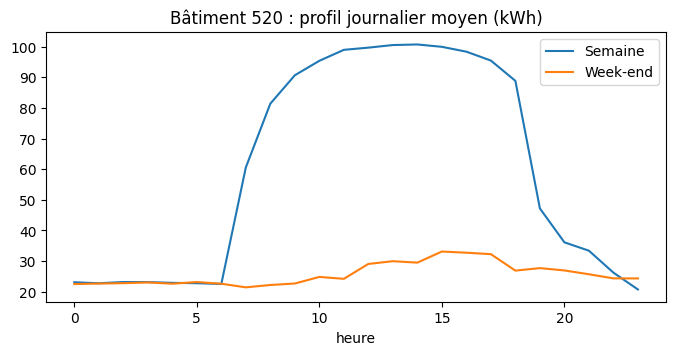


Moyenne par lundi (kWh) :
jour
2016-05-16    52.0
2016-05-23    54.3
2016-05-30    33.2
2016-06-06    73.1
2016-06-13    66.6
Name: meter_reading, dtype: float64

Heures météo site 3 sur la fenêtre : 744 / 744
air_temperature manquantes : 0


In [73]:
import matplotlib.pyplot as plt

# 1. Extraction et séries horaires
b = electricity_office[electricity_office['building_id'] == 520].copy()
b['heure'] = b['timestamp'].dt.hour
b['we'] = b['timestamp'].dt.dayofweek >= 5
print("Lignes :", len(b), "| site :", buildings.loc[buildings['building_id'] == 520, 'site_id'].iloc[0])

# 2. Profil moyen par heure : semaine vs week-end
prof = b.pivot_table(index='heure', columns='we', values='meter_reading', aggfunc='mean')
prof.columns = ['Semaine', 'Week-end']
prof.plot(figsize=(8, 3.5), title="Bâtiment 520 : profil journalier moyen (kWh)")
plt.show()

# 3. Le jour férié (lundi 30 mai 2016) comparé aux autres lundis
b['jour'] = b['timestamp'].dt.date
moy_jour = b.groupby('jour')['meter_reading'].mean()
lundis = moy_jour[pd.to_datetime(moy_jour.index).dayofweek == 0]
print("\nMoyenne par lundi (kWh) :")
print(lundis.round(1))

# 4. Météo du site 3 sur la même fenêtre
w3 = weather[weather['site_id'] == 3].set_index('timestamp')
fenetre = b['timestamp']
print("\nHeures météo site 3 sur la fenêtre :", w3.index.isin(fenetre).sum(), "/ 744")
print("air_temperature manquantes :", w3.loc[w3.index.isin(fenetre), 'air_temperature'].isna().sum())

In [74]:
print(prof.round(1).T.to_string())

heure       0     1     2     3     4     5     6     7     8     9     10    11    12     13     14     15    16    17    18    19    20    21    22    23
Semaine   23.1  22.8  23.2  23.2  22.9  22.8  22.5  60.6  81.4  90.7  95.4  99.0  99.7  100.6  100.7  100.0  98.4  95.5  88.9  47.2  36.1  33.4  26.2  20.7
Week-end  22.5  22.7  22.8  23.0  22.6  23.2  22.6  21.4  22.2  22.7  24.8  24.2  29.1   30.0   29.5   33.1  32.7  32.3  26.9  27.7  27.0  25.7  24.4  24.3


In [75]:
print("Heure du pic solaire :", solar_final.groupby(solar_final['DATE_TIME'].dt.hour)['ENERGIE_KWH'].mean().idxmax())
print("Heure du pic bureau  :", prof['Semaine'].idxmax())

Heure du pic solaire : 11
Heure du pic bureau  : 14


In [76]:
# 1. Préparer la consommation du bâtiment alignée sur les 744 h solaires
b = electricity_office[electricity_office['building_id'] == 520][['timestamp', 'meter_reading']].copy()
b['DATE_TIME'] = b['timestamp'] + pd.Timedelta(days=2)
b['DATE_TIME'] = b['DATE_TIME'].apply(lambda d: d.replace(year=2020))
b = b.rename(columns={'meter_reading': 'CONSO_KWH'})[['DATE_TIME', 'CONSO_KWH']]

# 2. Fusion avec la production
sb = solar_final.merge(b, on='DATE_TIME', how='inner', validate='one_to_one')
print("Smart Building brut :", sb.shape)

# 3. Calcul de k pour couvrir x % de la consommation sur la période
conso_tot = sb['CONSO_KWH'].sum()
prod_tot = sb['ENERGIE_KWH'].sum()
print("Consommation totale (kWh) :", round(conso_tot))
print("Production totale centrale (kWh) :", round(prod_tot))
for couverture in [0.5, 0.75, 1.0]:
    k = couverture * conso_tot / prod_tot
    print(f"Couverture {int(couverture*100)} % -> k = {k:.5f}")

Smart Building brut : (744, 11)
Consommation totale (kWh) : 36309
Production totale centrale (kWh) : 4836774
Couverture 50 % -> k = 0.00375
Couverture 75 % -> k = 0.00563
Couverture 100 % -> k = 0.00751


In [77]:
k = 0.75 * conso_tot / prod_tot
print("k =", round(k, 5))

sb['PROD_KWH'] = sb['ENERGIE_KWH'] * k
sb['E_NET_KWH'] = sb['CONSO_KWH'] - sb['PROD_KWH']          # >0 : achat réseau, <0 : surplus
sb['AUTOCONSO_KWH'] = np.minimum(sb['CONSO_KWH'], sb['PROD_KWH'])
sb['SURPLUS_KWH'] = (sb['PROD_KWH'] - sb['CONSO_KWH']).clip(lower=0)
sb['ACHAT_RESEAU_KWH'] = (sb['CONSO_KWH'] - sb['PROD_KWH']).clip(lower=0)

# Météo ASHRAE du site 3 (température de l'air), alignée sur les mêmes dates
w3 = weather[weather['site_id'] == 3][['timestamp', 'air_temperature']].copy()
w3['DATE_TIME'] = (w3['timestamp'] + pd.Timedelta(days=2)).apply(lambda d: d.replace(year=2020))
sb = sb.merge(w3[['DATE_TIME', 'air_temperature']], on='DATE_TIME', how='left', validate='one_to_one')

print(sb.shape, "| NaN :", sb.isna().sum().sum())
print("Production simulée (kWh) :", round(sb['PROD_KWH'].sum()))
print("Heures avec surplus :", (sb['SURPLUS_KWH'] > 0).sum(), "/ 744")
print("Taux d'autoconsommation (autoconso / production) :", round(sb['AUTOCONSO_KWH'].sum() / sb['PROD_KWH'].sum(), 3))
print("Taux de couverture (autoconso / consommation) :", round(sb['AUTOCONSO_KWH'].sum() / sb['CONSO_KWH'].sum(), 3))
print("Énergie achetée au réseau (kWh) :", round(sb['ACHAT_RESEAU_KWH'].sum()))

sb.to_csv('/kaggle/working/smart_building.csv', index=False)

k = 0.00563
(744, 17) | NaN : 0
Production simulée (kWh) : 27232
Heures avec surplus : 178 / 744
Taux d'autoconsommation (autoconso / production) : 0.707
Taux de couverture (autoconso / consommation) : 0.53
Énergie achetée au réseau (kWh) : 17070


In [78]:
pd.set_option('display.max_columns', None)   # bech ywarrik les colonnes lkol

print("Dimensions :", sb.shape)
display(sb.head(10))      # awel 10 lignes
display(sb.tail(5))       # a5er 5 lignes
sb.info()                 # types + valeurs non nulles
display(sb.describe().round(2))   # statistiques

Dimensions : (744, 17)


,DATE_TIME,ENERGIE_KWH,PUISSANCE_MOY_KW,NB_PAS,NB_CORRIGES,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,IRRADIATION,NB_PAS_METEO,METEO_CORRIGEE,CONSO_KWH,PROD_KWH,E_NET_KWH,AUTOCONSO_KWH,SURPLUS_KWH,ACHAT_RESEAU_KWH,air_temperature
0,2020-05-15 00:00:00,0.000000,0.000000,4,4,25.012697,22.643083,0.000000,4,0,22.26,0.000000,22.260000,0.000000,0.000000,22.260000,17.2
1,2020-05-15 01:00:00,0.000000,0.000000,4,2,24.667328,22.411960,0.000000,4,0,21.77,0.000000,21.770000,0.000000,0.000000,21.770000,17.8
2,2020-05-15 02:00:00,0.000000,0.000000,4,4,24.986837,23.512072,0.000000,4,0,22.22,0.000000,22.220000,0.000000,0.000000,22.220000,17.2
3,2020-05-15 03:00:00,0.000000,0.000000,4,4,24.954589,24.126433,0.000000,4,0,21.94,0.000000,21.940000,0.000000,0.000000,21.940000,17.2
4,2020-05-15 04:00:00,0.000000,0.000000,4,1,24.276670,22.133106,0.000000,4,0,21.70,0.000000,21.700000,0.000000,0.000000,21.700000,17.2
5,2020-05-15 05:00:00,0.000000,0.000000,4,3,24.274983,23.020118,0.000216,4,0,21.45,0.000000,21.450000,0.000000,0.000000,21.450000,17.2
6,2020-05-15 06:00:00,1246.873724,1246.873724,4,2,24.073951,22.973985,0.043243,4,0,21.61,7.020150,14.589850,7.020150,0.000000,14.589850,16.7
7,2020-05-15 07:00:00,4262.353631,4262.353631,4,0,24.889582,28.806721,0.147561,4,0,22.31,23.997909,-1.687909,22.310000,1.687909,0.000000,17.2
8,2020-05-15 08:00:00,9110.836101,9110.836101,4,0,26.160302,36.585317,0.316280,4,0,67.03,51.295840,15.734160,51.295840,0.000000,15.734160,17.2
9,2020-05-15 09:00:00,12302.173661,12302.173661,4,0,27.644042,42.923461,0.439623,4,0,89.23,69.263713,19.966287,69.263713,0.000000,19.966287,16.7


,DATE_TIME,ENERGIE_KWH,PUISSANCE_MOY_KW,NB_PAS,NB_CORRIGES,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,IRRADIATION,NB_PAS_METEO,METEO_CORRIGEE,CONSO_KWH,PROD_KWH,E_NET_KWH,AUTOCONSO_KWH,SURPLUS_KWH,ACHAT_RESEAU_KWH,air_temperature
739,2020-06-17 19:00:00,0.0,0.0,4,0,23.367776,22.418035,0.0,4,0,69.14,0.0,69.14,0.0,0.0,69.14,26.7
740,2020-06-17 20:00:00,0.0,0.0,4,0,22.918254,21.024839,0.0,4,0,40.78,0.0,40.78,0.0,0.0,40.78,26.7
741,2020-06-17 21:00:00,0.0,0.0,4,0,22.981533,21.735511,0.0,4,0,38.25,0.0,38.25,0.0,0.0,38.25,27.2
742,2020-06-17 22:00:00,0.0,0.0,4,0,22.271179,21.060298,0.0,4,0,25.85,0.0,25.85,0.0,0.0,25.85,27.8
743,2020-06-17 23:00:00,0.0,0.0,4,0,22.004218,20.815293,0.0,4,0,19.63,0.0,19.63,0.0,0.0,19.63,26.1


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 744 entries, 0 to 743
Data columns (total 17 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   DATE_TIME            744 non-null    datetime64[ns]
 1   ENERGIE_KWH          744 non-null    float64       
 2   PUISSANCE_MOY_KW     744 non-null    float64       
 3   NB_PAS               744 non-null    int64         
 4   NB_CORRIGES          744 non-null    int64         
 5   AMBIENT_TEMPERATURE  744 non-null    float64       
 6   MODULE_TEMPERATURE   744 non-null    float64       
 7   IRRADIATION          744 non-null    float64       
 8   NB_PAS_METEO         744 non-null    int64         
 9   METEO_CORRIGEE       744 non-null    int64         
 10  CONSO_KWH            744 non-null    float64       
 11  PROD_KWH             744 non-null    float64       
 12  E_NET_KWH            744 non-null    float64       
 13  AUTOCONSO_KWH        744 non-null  

,DATE_TIME,ENERGIE_KWH,PUISSANCE_MOY_KW,NB_PAS,NB_CORRIGES,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,IRRADIATION,NB_PAS_METEO,METEO_CORRIGEE,CONSO_KWH,PROD_KWH,E_NET_KWH,AUTOCONSO_KWH,SURPLUS_KWH,ACHAT_RESEAU_KWH,air_temperature
count,744,744.00,744.00,744.0,744.00,744.00,744.00,744.00,744.0,744.00,744.00,744.00,744.00,744.00,744.00,744.00,744.00
mean,2020-06-01 18:28:03.870967808,6501.04,6501.04,4.0,0.16,25.46,30.82,0.22,4.0,0.03,48.80,36.60,12.20,25.86,10.74,22.94,21.40
min,2020-05-15 00:00:00,0.00,0.00,4.0,0.00,20.68,18.29,0.00,4.0,0.00,16.92,0.00,-125.91,0.00,0.00,0.00,7.20
25%,2020-05-24 17:45:00,0.00,0.00,4.0,0.00,22.70,21.13,0.00,4.0,0.00,22.76,0.00,3.62,0.00,0.00,3.62,17.20
50%,2020-06-02 11:30:00,706.22,706.22,4.0,0.00,24.49,24.72,0.03,4.0,0.00,27.76,3.98,21.41,3.98,0.00,21.41,22.20
75%,2020-06-10 05:15:00,13463.50,13463.50,4.0,0.00,27.83,41.18,0.46,4.0,0.00,82.28,75.80,29.05,39.16,0.00,29.05,25.00
max,2020-06-17 23:00:00,26869.82,26869.82,4.0,4.00,34.99,61.49,1.01,4.0,4.00,128.92,151.28,119.77,124.43,125.91,119.77,35.60
std,NaN,8269.29,8269.29,0.0,0.68,3.31,11.87,0.29,0.0,0.29,34.79,46.56,39.96,35.29,25.57,21.21,5.35


In [79]:
jour = sb[sb['DATE_TIME'].dt.date == pd.to_datetime('2020-05-18').date()]
display(jour[['DATE_TIME','CONSO_KWH','PROD_KWH','E_NET_KWH','SURPLUS_KWH','ACHAT_RESEAU_KWH']].round(2))

,DATE_TIME,CONSO_KWH,PROD_KWH,E_NET_KWH,SURPLUS_KWH,ACHAT_RESEAU_KWH
72,2020-05-18 00:00:00,25.57,0.00,25.57,0.00,25.57
73,2020-05-18 01:00:00,26.25,0.00,26.25,0.00,26.25
74,2020-05-18 02:00:00,25.78,0.00,25.78,0.00,25.78
75,2020-05-18 03:00:00,25.96,0.00,25.96,0.00,25.96
76,2020-05-18 04:00:00,25.85,0.00,25.85,0.00,25.85
77,2020-05-18 05:00:00,25.46,0.00,25.46,0.00,25.46
78,2020-05-18 06:00:00,27.51,7.05,20.46,0.00,20.46
79,2020-05-18 07:00:00,25.20,29.08,-3.88,3.88,0.00
80,2020-05-18 08:00:00,59.39,19.36,40.03,0.00,40.03
81,2020-05-18 09:00:00,70.26,19.73,50.53,0.00,50.53
